# 3. Input-rate limits without coupling distant stages

**Goal:** the previous tracking problem, but with smoother acceleration.
Introduce the memory state $w_k=u_{k-1}$ and set $w_{k+1}=u_k$.
The augmented state is $x_k=(p_k,v_k,w_k)$.

Add $\tfrac12\eta(u_k-w_k)^2$ to the running cost and impose
$$|u_k-w_k|\le0.3,\qquad w_0=0,\qquad\eta=1.5.$$
The same dynamics, position/velocity target, and bounds from Tutorial 2 remain.
The increment is **per sample**, not jerk per second; a jerk limit would include $\Delta t$.


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

## 1. Augmented dynamics

In [2]:
N, nx, nu = 30, 3, 1
dt, eta, delta_max = 0.2, 1.5, 0.3
A = np.tile([[1.0, dt, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 0.0]], (N, 1, 1))
B = np.tile([[0.5 * dt**2], [dt], [1.0]], (N, 1, 1))
b = np.zeros((N, nx))
x0 = np.zeros(nx)
target = np.array([2.0, 0.0, 0.0])

## 2. Cost with a cross term
$\tfrac12\eta(u-w)^2=\tfrac12\eta u^2-\eta uw+\tfrac12\eta w^2$.
This adds entries to `R`, `S`, and `Q`. Convexity concerns the **full** block Hessian,
not just `Q` and `R` separately.

In [3]:
Q = np.tile(np.diag([4.0, 0.3, eta]), (N + 1, 1, 1))
Q[-1] = np.diag([20.0, 2.0, 0.0])
R = (0.15 + eta) * np.ones((N, nu, nu))
S = np.zeros((N, nu, nx))
S[:, 0, 2] = -eta
q = -(Q @ target)
r = np.zeros((N, nu))
objective_offset = 0.5 * sum(target @ Qk @ target for Qk in Q)

## 3. Stage-local constraints
The last two rows encode the input increment using the memory state.

In [4]:
# Columns: [u, position, velocity, previous_u].
G = np.zeros((N + 1, 6, nu + nx))
h = np.ones((N + 1, 6))
G[:N, 0, 0], G[:N, 1, 0] = 1.0, -1.0
h[:, :2] = 1.2
G[:, 2, 2], G[:, 3, 2] = 1.0, -1.0
h[:, 2:4] = 1.0
G[:N, 4, 0], G[:N, 4, 3] = 1.0, -1.0
G[:N, 5, 0], G[:N, 5, 3] = -1.0, 1.0
h[:, 4:] = delta_max
F = np.eye(nx)[:2]       # Only position and velocity are fixed at the end.
f = target[:2].copy()

## 4. Give the arrays to ICORE and solve

`[u, x]` is the column order in each constraint row. The block cost is
$\tfrac12x^TQx + u^TSx + \tfrac12u^TRu + q^Tx + r^Tu$.
`F @ x[N] = f` is an optional terminal equality. An empty `F, f` means none.

The kernel and counters below come from the actual solve. A factorization policy
is **not** claimed to be a trace of every operation. Set `DETAILED=True` above
for an additional diagnostic replay; it is separate from solve timing.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE) as solver:
    solution = solver.solve()
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

# Solver returns your original coordinates, including when presolve was applied.
x = solution["x"]        # Shape (N + 1, nx).
u = solution["u"]        # Shape (N, nu); there is no terminal control.
print("Initial state:", x[0])
print("Final state:", x[-1])
print("First input:", u[0])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 9
Native solve (ms),0.213000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
4.441e-16,7.105e-15,1.025e-12,4.441e-16,1.204e-24,60.076481,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

Initial state: [0. 0. 0.]
Final state: [2.00000000e+00 1.20399997e-24 8.32780088e-04]
First input: [0.3]


## 5. Results

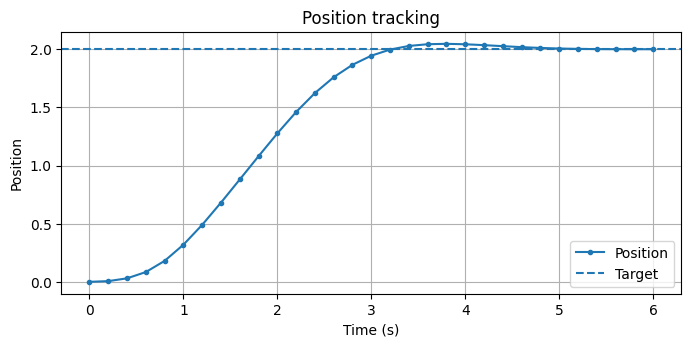

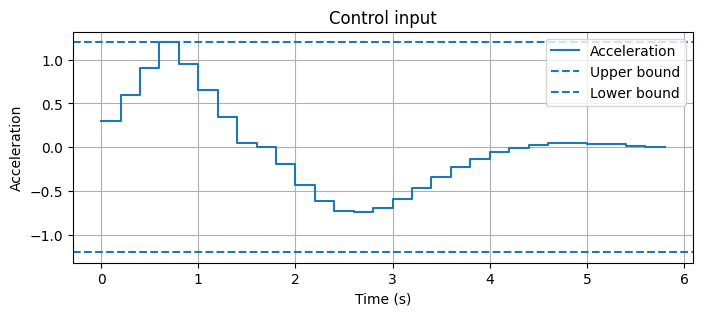

Largest absolute input increment: 0.3000000000000001


In [6]:
time_x = dt * np.arange(N + 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(time_x, x[:, 0], marker=".", label="Position")
ax.axhline(target[0], linestyle="--", label="Target")
ax.set(xlabel="Time (s)", ylabel="Position", title="Position tracking")
ax.grid(True)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.step(dt * np.arange(N), u[:, 0], where="post", label="Acceleration")
ax.axhline(1.2, linestyle="--", label="Upper bound")
ax.axhline(-1.2, linestyle="--", label="Lower bound")
ax.set(xlabel="Time (s)", ylabel="Acceleration", title="Control input")
ax.grid(True)
ax.legend()
plt.show()

delta_u = u[:, 0] - x[:-1, 2]
print("Largest absolute input increment:", np.max(np.abs(delta_u)))
assert np.max(np.abs(delta_u)) <= delta_max + TOLERANCE

## Modeling tip
Adding one memory state preserves nearest-neighbor dynamics. It avoids introducing an arbitrary
cross-stage constraint into an interface designed for stage-local rows. It also increases the
state dimension: measure the tradeoff rather than assuming every augmentation is faster.

Next: [soft constraints](04_soft_corridor.ipynb).